# Ứng dụng 1 — Phân tích giỏ hàng (Market Basket Analysis)

Ứng dụng tìm các nhóm sản phẩm thường được mua cùng nhau trong một cửa hàng bán lẻ trực tuyến và sinh các luật kết hợp (association rules) $X \rightarrow Y$, với $X$, $Y$ là hai tập sản phẩm khác rỗng, rời nhau. Một luật được giữ khi $\text{support}(X \cup Y) \ge \text{minsup}$, tức tỷ lệ hóa đơn chứa cả $X$ và $Y$ đạt ngưỡng support tối thiểu, và $\text{confidence}(X \rightarrow Y) \ge \text{minconf}$, tức tỷ lệ hóa đơn chứa $Y$ trong số các hóa đơn chứa $X$ đạt ngưỡng confidence tối thiểu; định nghĩa đầy đủ được trình bày ở mục 6. Top-10 luật theo lift được trình bày cùng diễn giải ý nghĩa kinh doanh.

Mọi tập phổ biến và luật kết hợp đều được sinh bằng cài đặt FPClose [1] của nhóm thông qua dòng lệnh `demo.jl`; nhóm không sử dụng mlxtend hay thư viện khai thác tập phổ biến nào khác. Python (pandas, openpyxl, matplotlib, jinja2) chỉ được dùng để đọc và biến đổi dữ liệu, trình bày kết quả; mã nguồn nằm trong `applications/application_01/market_basket.py`.

**Dữ liệu.** UCI Online Retail [2]: 541.909 dòng giao dịch của một cửa hàng trực tuyến tại Vương quốc Anh trong giai đoạn 12/2010–12/2011, giấy phép CC BY 4.0.

> [1] G. Grahne và J. Zhu, "Fast Algorithms for Frequent Itemset Mining Using FP-Trees," *IEEE Transactions on Knowledge and Data Engineering*, vol. 17, no. 10, pp. 1347–1362, 2005. DOI: [10.1109/TKDE.2005.166](https://doi.org/10.1109/TKDE.2005.166)  
> [2] D. Chen, *Online Retail* [Dataset], UCI Machine Learning Repository, 2015. DOI: [10.24432/C5BW33](https://doi.org/10.24432/C5BW33)

**Nội dung:** (1) Môi trường thực thi · (2) Cấu hình · (3) Tiền xử lý dữ liệu · (4) Khai thác tập phổ biến đóng · (5) Khảo sát minsup và ảnh hưởng của hóa đơn rất dài · (6) Sinh luật kết hợp · (7) Các luật tiêu biểu: top-10 theo lift, top-10 đa dạng, độ nhạy theo minsup · (8) Diễn giải ý nghĩa kinh doanh

## 1. Môi trường thực thi

Notebook sử dụng kernel Python 3. Khi chạy trên Google Colab, ô dưới đây tải repository theo nhánh `BRANCH`, cài Julia `JULIA_VERSION` (1.13.4, trùng phiên bản trên máy đo chính thức) từ bản phát hành chính thức và cài các gói Julia bằng `Pkg.instantiate()`. Khi chạy local, gốc repository là thư mục cha gần nhất chứa `Project.toml`, và lệnh `julia` cần có trong `PATH`. Các thư viện Python còn thiếu (`pandas`, `openpyxl`, `matplotlib`, `jinja2`) được cài bằng `pip`, sau đó module `market_basket` được nạp.

In [23]:
import os, sys, subprocess, importlib, importlib.util
from pathlib import Path

REPO_URL = 'https://github.com/DRAGON-1312/FPClose.git'
BRANCH = 'feature/app1-market-basket'   # nhánh mã nguồn dùng khi chạy trên Colab
REPO_DIR = '/content/FPClose'
JULIA_VERSION = '1.13.4'                # cùng phiên bản với máy đo chính thức (results/ENVIRONMENT.md)
IN_COLAB = os.path.isdir('/content')

def julia_version(exe='julia'):
    """Chuỗi `julia --version` của lệnh `exe`; rỗng nếu không chạy được."""
    try:
        return subprocess.run([exe, '--version'], capture_output=True, text=True).stdout.strip()
    except (FileNotFoundError, PermissionError):
        return ''

if IN_COLAB:
    if not os.path.isdir(os.path.join(REPO_DIR, '.git')):
        subprocess.run(['git', 'clone', '--quiet', REPO_URL, REPO_DIR], check=True)
    subprocess.run(['git', '-C', REPO_DIR, 'fetch', '--quiet', 'origin', BRANCH], check=True)
    subprocess.run(['git', '-C', REPO_DIR, 'checkout', '--quiet', '-B', BRANCH, 'FETCH_HEAD'], check=True)
    repo = Path(REPO_DIR)
    # Julia từ tarball chính thức vào /usr (bỏ qua nếu đã đúng phiên bản). Colab có sẵn một bản Julia khác ở
    # /usr/local/bin (đứng trước /usr/bin trong PATH) nên trỏ symlink về bản vừa cài, chỉ khi bản đó đúng phiên bản.
    want = f'julia version {JULIA_VERSION}'
    if julia_version() != want:
        if julia_version('/usr/bin/julia') != want:
            major_minor = '.'.join(JULIA_VERSION.split('.')[:2])
            url = (f'https://julialang-s3.julialang.org/bin/linux/x64/{major_minor}/'
                   f'julia-{JULIA_VERSION}-linux-x86_64.tar.gz')
            subprocess.run(['curl', '-fsSL', '-o', '/tmp/julia.tar.gz', url], check=True)
            subprocess.run(['tar', '-xzf', '/tmp/julia.tar.gz', '-C', '/usr', '--strip-components', '1'], check=True)
            os.remove('/tmp/julia.tar.gz')
        if julia_version('/usr/bin/julia') == want and os.path.isdir('/usr/local/bin'):
            subprocess.run(['ln', '-sf', '/usr/bin/julia', '/usr/local/bin/julia'], check=True)
    subprocess.run(['julia', f'--project={REPO_DIR}', '-e', 'using Pkg; Pkg.instantiate(); Pkg.precompile()'],
                   check=True)
else:
    repo = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / 'Project.toml').is_file())
print('Julia:', julia_version() or 'không tìm thấy lệnh julia (cần cho mục 4–7)')

for pkg in ('pandas', 'openpyxl', 'matplotlib', 'jinja2'):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

app_path = str(repo / 'applications' / 'application_01')
if app_path not in sys.path:
    sys.path.insert(0, app_path)
import market_basket as mb
mb = importlib.reload(mb)   # nạp lại khi module được sửa trong lúc chạy notebook
ROOT = mb.find_root()
print('Gốc repository:', ROOT, '| Colab:', IN_COLAB)

Julia: julia version 1.13.4
Gốc repository: C:\HCMUS\Data Mining\FPClose\FPClose | Colab: False


## 2. Cấu hình

Mọi tham số có ảnh hưởng đến kết quả được khai báo tại ô dưới đây:
- **Dữ liệu và làm sạch:** nguồn tải (`UCI_URL`; bản sao `HF_URL` nếu có), mã băm `SHA256` của file gốc, danh sách mã không phải sản phẩm `NON_PRODUCT` cùng các tiền tố tương ứng, và id của item đầu tiên `ID_START`.
- **Khai thác:** hai ngưỡng sinh luật `MINSUP` = 1% và `MINCONF` = 0,6 (chốt dựa trên khảo sát ở mục 5), số luật trình bày `TOP_K` = 10, các mức khảo sát `MINSUP_SURVEY`, ngưỡng độ nhạy `MINSUP_SENS` = 2% (mục 7.3), các tham số `LONG_THRESHOLDS`, `LONG_MINSUPS`, `LONG_RULES_MAX_LEN` của thí nghiệm ở mục 5.1, và giới hạn thời gian `SURVEY_TIMEOUT` cho mỗi lần chạy `demo.jl`.

In [24]:
import pandas as pd
from IPython.display import Image, display

APP = ROOT / 'applications' / 'application_01'
UCI_URL = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
HF_URL = ''                                   # bản sao trên Hugging Face (nếu có)
SHA256 = '43465A06F2CCF7C8B5BD2892BC7DEFB52F97487934FE93B16AE4C3936424676D'
NON_PRODUCT = mb.NON_PRODUCT                  # mã không phải sản phẩm (so sau strip().upper())
NON_PRODUCT_PREFIXES = mb.NON_PRODUCT_PREFIXES  # tiền tố mã không phải sản phẩm
STOCK_CODE_PATTERN = mb.STOCK_CODE_PATTERN    # chỉ dùng để thống kê mã lệch mẫu, không dùng để loại
ID_START = mb.ID_START                        # id item đầu tiên (read_spmf nhận id >= 0)

# Khai thác bằng FPClose của nhóm (mục 4–7)
TX_PATH = APP / 'data' / 'transactions.txt'   # đầu vào của demo.jl (tạo ở mục 3.4)
OUT_DIR = APP / 'out'                         # output thô của FPClose (không commit)
MINSUP_SURVEY = [0.03, 0.02, 0.015, 0.01, 0.005, 0.003, 0.002]  # mục 5; mức < 1% chỉ để khảo sát, không sinh luật
SURVEY_TIMEOUT = 600                          # giới hạn thời gian (giây) cho mỗi lần chạy demo.jl
MINSUP = 0.01                                 # ĐÃ CHỐT dựa trên khảo sát mục 5: minsup khai thác và sinh luật
MINCONF = 0.6                                 # ĐÃ CHỐT: ngưỡng confidence
TOP_K = 10                                    # số luật lấy theo lift
MINSUP_SENS = 0.02                            # minsup cao hơn để khảo sát độ nhạy của luật (mục 7.3)
LONG_THRESHOLDS = [500, 200]                  # mục 5.1: bỏ hóa đơn có >= t sản phẩm, với mỗi t
LONG_MINSUPS = [0.01, 0.002]                  # mục 5.1: các mức minsup dùng để so với dữ liệu gốc
LONG_RULES_MAX_LEN = 200                      # mục 5.1: ngưỡng độ dài khi so sánh luật ở MINSUP
RULE_COLS = ['rank_all', 'antecedent', 'consequent', 'support', 'confidence', 'lift', 'count']  # cột hiển thị

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)
print('Thư mục ứng dụng:', APP)
print('NON_PRODUCT:', NON_PRODUCT, '| tiền tố:', NON_PRODUCT_PREFIXES, '| ID_START:', ID_START)
print('MINSUP_SURVEY:', MINSUP_SURVEY, '| SURVEY_TIMEOUT:', SURVEY_TIMEOUT)
print('MINSUP:', MINSUP, '| MINCONF:', MINCONF, '| TOP_K:', TOP_K, '| MINSUP_SENS:', MINSUP_SENS)

Thư mục ứng dụng: C:\HCMUS\Data Mining\FPClose\FPClose\applications\application_01
NON_PRODUCT: ('POST', 'DOT', 'M', 'D', 'C2', 'CRUK', 'PADS', 'S', 'B', 'BANK CHARGES', 'AMAZONFEE') | tiền tố: ('GIFT_', 'DCGS') | ID_START: 1
MINSUP_SURVEY: [0.03, 0.02, 0.015, 0.01, 0.005, 0.003, 0.002] | SURVEY_TIMEOUT: 600
MINSUP: 0.01 | MINCONF: 0.6 | TOP_K: 10 | MINSUP_SENS: 0.02


## 3. Tiền xử lý dữ liệu

Mỗi giao dịch được định nghĩa là một hóa đơn (InvoiceNo) và mỗi item là một mã sản phẩm (StockCode). Phần này trình bày lần lượt các quyết định biến đổi dữ liệu gốc thành giao dịch, theo đúng định dạng đầu vào của cài đặt FPClose của nhóm.

### 3.1 Tải và đọc dữ liệu

File `Online Retail.xlsx` được tải từ UCI (hoặc `HF_URL`) vào `data/raw/` nếu chưa có, và được kiểm tra mã băm SHA-256 để mọi lần chạy sử dụng cùng một phiên bản dữ liệu. Các cột InvoiceNo, StockCode và Description được đọc dưới dạng chuỗi để giữ nguyên các mã có chữ cái (hóa đơn hủy bắt đầu bằng 'C', mã sản phẩm có hậu tố chữ). Kết quả đọc được lưu cache, gắn với mã băm của file gốc.

In [25]:
df_raw = mb.load_raw(APP, UCI_URL, SHA256, hf_url=HF_URL)
print(f'{len(df_raw):,} dòng, {df_raw.shape[1]} cột')
display(mb.styled(df_raw.head(), hide_index=False))

541,909 dòng, 8 cột


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.550000,17850.000000,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.390000,17850.000000,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.750000,17850.000000,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.390000,17850.000000,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.390000,17850.000000,United Kingdom


**Kết quả.** Dữ liệu gồm 541.909 dòng và 8 cột; mã băm SHA-256 của file khớp với giá trị khai báo. Mỗi dòng tương ứng với một sản phẩm trong một hóa đơn, do đó dữ liệu cần được gom theo InvoiceNo để tạo thành giao dịch.

### 3.2 Chẩn đoán dữ liệu

Trước khi loại bỏ bất kỳ dòng nào, các vấn đề có thể ảnh hưởng đến giao dịch được định lượng: hóa đơn hủy, số lượng hoặc đơn giá không dương, mô tả rỗng, mã thiếu và CustomerID thiếu. StockCode (sau khi chuẩn hóa bằng `strip().upper()`) được đối chiếu với mẫu `^\d{5}[A-Z]{0,2}$` của mã sản phẩm thông thường; các mã lệch mẫu được liệt kê làm căn cứ xây dựng danh sách `NON_PRODUCT`. Các mã có nhiều mô tả cũng được thống kê để chọn tên hiển thị theo một quy tắc tất định.

In [26]:
diagnosis = mb.diagnose(df_raw, pattern=STOCK_CODE_PATTERN)
for name, table in diagnosis.items():
    print('==', name)
    display(mb.styled(table))

== summary


chỉ số,số lượng
Tổng số dòng,541909
Số hóa đơn phân biệt,25900
Số hóa đơn hủy (InvoiceNo bắt đầu bằng 'C'/'c'),3836
Số dòng thuộc hóa đơn hủy,9288
Số dòng Quantity <= 0 hoặc thiếu,10624
Số dòng UnitPrice <= 0 hoặc thiếu,2517
Số dòng Description rỗng,1454
Số dòng InvoiceNo thiếu/rỗng,0
Số dòng StockCode thiếu/rỗng,0
Số dòng thiếu CustomerID (không loại),135080


== irregular_codes


stock_code,description,n_rows
POST,POSTAGE,1256
DOT,DOTCOM POSTAGE,710
M,Manual,572
C2,CARRIAGE,144
D,Discount,77
S,SAMPLES,63
BANK CHARGES,Bank Charges,37
AMAZONFEE,AMAZON FEE,34
CRUK,CRUK Commission,16
DCGSSGIRL,GIRLS PARTY BAG,13


== multi_description


stock_code,n_descriptions,descriptions
20713,8,Found | JUMBO BAG OWLS | Marked as 23343 | found | wrongly coded 23343 | wrongly coded-23343 | wrongly marked 23343 | wrongly marked. 23343 in box
23084,7,Amazon | RABBIT NIGHT LIGHT | add stock to allocate online orders | allocate stock for dotcom orders ta | for online retail orders | temp adjustment | website fixed
21830,6,"? | ASSORTED CREEPY CRAWLIES | MERCHANT CHANDLER CREDIT ERROR, STO | OOPS ! adjustment | damaged | sold as 1"
85175,6,? sold as sets? | Amazon sold sets | CACTI T-LIGHT CANDLES | check | dotcom sold sets | wrongly sold sets
21181,5,PLEASE ONE PERSON METAL SIGN | adjustment | check | dotcom | on cargo order


**Kết quả.** Dữ liệu gồm 25.900 hóa đơn, trong đó 3.836 hóa đơn hủy (9.288 dòng). 135.080 dòng (24,9%) không có CustomerID và được giữ lại, vì giao dịch được xác định theo InvoiceNo. 32 mã lệch mẫu là các mã đặc biệt: phí vận chuyển (POST, DOT, C2), điều chỉnh kế toán (M, D, B, BANK CHARGES, AMAZONFEE, CRUK), hàng mẫu (S), phiếu quà tặng (GIFT_*), mã của kênh bán riêng (DCGS*) và PADS; toàn bộ được loại ở mục 3.3. Một số mã DCGS* và PADS có mô tả giống sản phẩm, nhưng mỗi mã xuất hiện trong không quá 13 hóa đơn, ít hơn ngưỡng thấp nhất được khảo sát (40 hóa đơn), nên không thể thuộc một tập phổ biến nào. Việc loại các mã này cũng không làm thay đổi support tuyệt đối của các itemset khác, vì bỏ một mã khỏi hóa đơn không làm hóa đơn mất bất kỳ itemset nào không chứa mã đó; ảnh hưởng duy nhất là tổng số giao dịch $N$ có thể giảm không đáng kể nếu một hóa đơn chỉ gồm các mã này. 638 mã có nhiều mô tả, chủ yếu do ghi chú điều chỉnh kho ("damaged", "wrongly coded"); tên hiển thị là mô tả xuất hiện nhiều nhất.

### 3.3 Làm sạch dữ liệu

Các bước được áp dụng theo thứ tự cố định: (1) loại dòng thiếu InvoiceNo hoặc StockCode; (2) loại hóa đơn hủy; (3) loại dòng có Quantity ≤ 0; (4) loại dòng có UnitPrice ≤ 0; (5) loại dòng có Description rỗng; (6) loại các mã thuộc `NON_PRODUCT` hoặc bắt đầu bằng `GIFT_`, `DCGS`. Các mã lệch mẫu khác (nếu có) chỉ được thống kê, không bị loại tự động.

In [27]:
df_clean, cleaning_steps = mb.clean(df_raw, non_product=NON_PRODUCT, prefixes=NON_PRODUCT_PREFIXES)
display(mb.styled(cleaning_steps))

bước,mô tả,số dòng bị loại,số dòng còn lại
0,Dữ liệu gốc,0,541909
1,InvoiceNo hoặc StockCode thiếu/rỗng,0,541909
2,Hóa đơn hủy (InvoiceNo bắt đầu bằng 'C'/'c'),9288,532621
3,Quantity <= 0 hoặc thiếu,1336,531285
4,UnitPrice <= 0 hoặc thiếu,1181,530104
5,Description rỗng,0,530104
6,"Mã không phải sản phẩm (AMAZONFEE, B, BANK CHARGES, C2, CRUK, D, DOT, M, PADS, POST, S; tiền tố GIFT_, DCGS)",2379,527725


**Kết quả.** Sau làm sạch còn 527.725 dòng (97,4%). Hóa đơn hủy chiếm phần lớn số dòng bị loại (9.288 dòng); ngoài ra có 1.336 dòng có số lượng không dương, 1.181 dòng có đơn giá không dương và 2.379 dòng thuộc mã không phải sản phẩm. Bước loại mô tả rỗng không loại thêm dòng nào, vì toàn bộ 1.454 dòng thiếu mô tả đã bị loại ở các bước trước.

### 3.4 Biến đổi thành giao dịch và ghi file SPMF

Mỗi giao dịch là **tập** các StockCode phân biệt trong một hóa đơn: số lượng không được sử dụng, các dòng trùng mã được gộp, và hóa đơn chỉ gồm một sản phẩm vẫn được giữ. Ví dụ, một hóa đơn gồm ba dòng 85123A (6 cái), 71053 (6 cái) và 85123A (2 cái) trở thành giao dịch {85123A, 71053}. Mỗi StockCode được ánh xạ sang một id nguyên liên tục bắt đầu từ `ID_START` = 1 theo thứ tự mã. Giao dịch được ghi vào `data/transactions.txt` theo định dạng SPMF (mỗi dòng một hóa đơn, các id tăng dần cách nhau bởi dấu cách), kèm bảng ánh xạ `data/item_map.csv` (id, StockCode, tên hiển thị, số hóa đơn chứa sản phẩm và support); file được đọc lại để kiểm tra tính hợp lệ sau khi ghi.

In [28]:
transactions, item_map, tx_info = mb.to_transactions(df_clean, id_start=ID_START)
print(tx_info)
display(mb.styled(item_map.head(10)))

spmf_files = mb.write_spmf(transactions, item_map, APP, id_start=ID_START)
for name, path in spmf_files.items():
    print(f'{name}: {path}')

{'n_rows': 527725, 'n_duplicate_rows_merged': 10471, 'n_transactions': 19773, 'n_items': 3791, 'id_start': 1}


id,stock_code,description,n_transactions,support_pct
1,10002,INFLATABLE POLITICAL GLOBE,71,0.359076
2,10080,GROOVY CACTUS INFLATABLE,22,0.111263
3,10120,DOGGY RUBBER,29,0.146665
4,10123C,HEARTS WRAPPING TAPE,3,0.015172
5,10124A,SPOTS ON RED BOOKCOVER TAPE,5,0.025287
6,10124G,ARMY CAMO BOOKCOVER TAPE,4,0.020230
7,10125,MINI FUNKY DESIGN TAPES,91,0.460224
8,10133,COLOURING PENCILS BROWN TUBE,196,0.991251
9,10135,COLOURING PENCILS BROWN TUBE,175,0.885045
10,11001,ASSTD DESIGN RACING CAR PEN,113,0.571486


transactions: C:\HCMUS\Data Mining\FPClose\FPClose\applications\application_01\data\transactions.txt
item_map: C:\HCMUS\Data Mining\FPClose\FPClose\applications\application_01\data\item_map.csv


**Kết quả.** 10.471 dòng trùng mã được gộp, tạo thành 19.773 giao dịch trên 3.791 item. Số giao dịch nhỏ hơn số hóa đơn không bị hủy (22.064) vì 2.291 hóa đơn chỉ gồm các dòng đã bị loại. Một số mã khác nhau có cùng mô tả (ví dụ 10133 và 10135), nên các bảng kết quả hiển thị tên sản phẩm kèm StockCode.

### 3.5 Thống kê giao dịch

Các đặc trưng của tập giao dịch được tổng hợp làm cơ sở chọn ngưỡng minsup: độ dài giỏ hàng, mật độ dữ liệu (độ dài trung bình chia cho số item), số hóa đơn rất dài (từ 100, 200 và 500 sản phẩm trở lên) và mười sản phẩm có support cao nhất. Histogram độ dài giỏ hàng được cắt tại phân vị 99.

In [29]:
tx_stats, top10_items = mb.transaction_stats(transactions, item_map)
display(mb.styled(tx_stats))
display(mb.styled(top10_items))

saved = mb.save_results(APP, cleaning_steps, tx_stats)
for name, path in saved.items():
    print(f'{name}: {path}')

chỉ số,giá trị
Số giao dịch (hóa đơn),19773.000000
Số item (sản phẩm),3791.000000
Độ dài giỏ trung bình,26.160000
Độ dài giỏ trung vị,15.000000
Độ dài giỏ p90,52.000000
Độ dài giỏ lớn nhất,1106.000000
Tỷ lệ hóa đơn 1 sản phẩm (%),7.586000
Mật độ (%) = độ dài TB / số item,0.690000
Số hóa đơn có >= 100 sản phẩm,636.000000
Tỷ lệ hóa đơn có >= 100 sản phẩm (%),3.217000


id,stock_code,description,n_transactions,support_pct
3310,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2265,11.455014
3294,85099B,JUMBO BAG RED RETROSPOT,2089,10.564912
1306,22423,REGENCY CAKESTAND 3 TIER,1988,10.054114
2659,47566,PARTY BUNTING,1685,8.521722
171,20725,LUNCH BAG RED RETROSPOT,1565,7.914833
3131,84879,ASSORTED COLOUR BIRD ORNAMENT,1455,7.358519
1105,22197,POPCORN HOLDER,1392,7.039903
1589,22720,SET OF 3 CAKE TINS PANTRY DESIGN,1385,7.004501
435,21212,PACK OF 72 RETROSPOT CAKE CASES,1320,6.675770
1272,22383,LUNCH BAG SUKI DESIGN,1284,6.493704


cleaning_steps: C:\HCMUS\Data Mining\FPClose\FPClose\applications\application_01\results\cleaning_steps.csv
transaction_stats: C:\HCMUS\Data Mining\FPClose\FPClose\applications\application_01\results\transaction_stats.csv


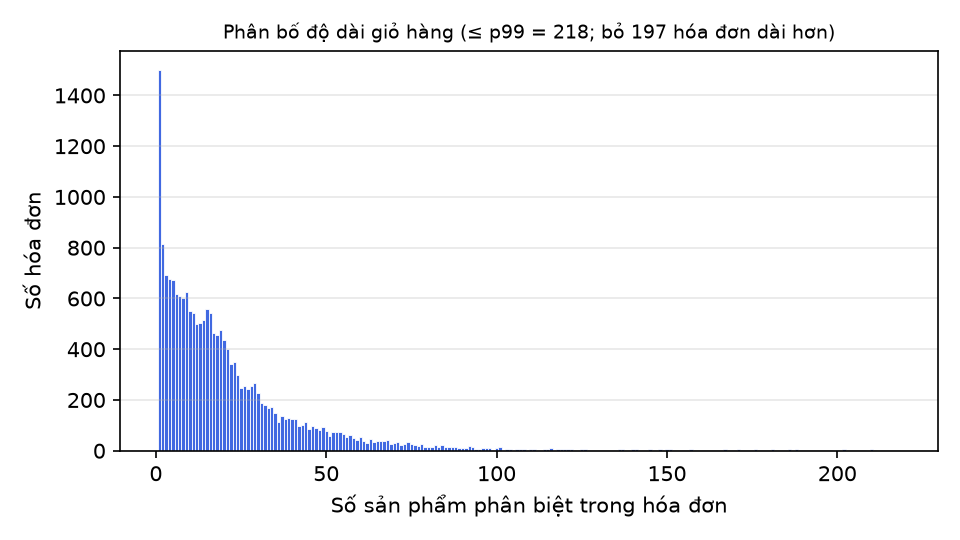

In [30]:
fig_path = mb.plot_basket_length(transactions, APP / 'results' / 'figures' / 'basket_length.png')
display(Image(filename=str(fig_path)))

**Kết quả.** Độ dài giỏ hàng có trung bình 26,2, trung vị 15 và lớn nhất 1.106 sản phẩm. Phân bố lệch phải, với 236 hóa đơn (1,2%) có từ 200 sản phẩm và 49 hóa đơn (0,25%) có từ 500 sản phẩm trở lên. Các hóa đơn rất dài này nhiều khả năng là đơn hàng bán sỉ (theo mô tả của bộ dữ liệu, nhiều khách hàng là người bán buôn), nhưng dữ liệu không ghi nhận trực tiếp loại khách hàng; các hóa đơn này được giữ lại, và ảnh hưởng của chúng được đánh giá ở mục 5.1. Mật độ chỉ 0,69%, tức dữ liệu rất thưa, tương tự Retail và Kosarak ở Chương 2. Sản phẩm phổ biến nhất có support 11,5%, nên minsup được khảo sát trong khoảng 0,2%–3%.

## 4. Khai thác tập phổ biến đóng

Một itemset $X$ là **đóng** (closed) nếu không tồn tại tập cha thực sự nào của $X$ có cùng support. Support của mọi tập phổ biến $Y$ được suy ra từ các tập đóng theo công thức $\sigma(Y) = \max\{\sigma(C) : C \text{ đóng},\ Y \subseteq C\}$, trong đó $\sigma(\cdot)$ là số giao dịch chứa một itemset. Vì vậy FPClose [1] chỉ cần khai thác các tập đóng; mọi tập phổ biến được khôi phục từ đó bằng bước recovery của nhóm và là đầu vào cho bước sinh luật ở mục 6. Ô thứ hai hiển thị mười tập đóng có từ hai sản phẩm trở lên với support cao nhất.

In [31]:
mining = mb.run_fpclose(ROOT, TX_PATH, MINSUP, OUT_DIR)
info = mining['info']
print(f"minsup = {MINSUP}: tối thiểu {info.get('minsup_count')} trên {info.get('transactions')} giao dịch")
print(f"Số tập phổ biến đóng: {info.get('closed_itemsets')} | số tập phổ biến: {info.get('frequent_itemsets')}")
print(f"Thời gian: khai thác {info.get('mining_seconds')} s, khôi phục {info.get('recovery_seconds')} s, "
      f"cả tiến trình (gồm khởi động Julia) {mining['wall_s']:.2f} s")

minsup = 0.01: tối thiểu 198 trên 19773 giao dịch
Số tập phổ biến đóng: 2026 | số tập phổ biến: 2026
Thời gian: khai thác 0.4416 s, khôi phục 0.0008 s, cả tiến trình (gồm khởi động Julia) 3.11 s


In [32]:
closed_df = mb.read_itemsets(mining['closed'], item_map, len(transactions))
display(mb.styled(closed_df[closed_df['size'] >= 2].head(10)))

items,size,support_count,support_pct,item_ids
JUMBO BAG PINK POLKADOT [22386] + JUMBO BAG RED RETROSPOT [85099B],2,825,4.172356,1275 3294
GREEN REGENCY TEACUP AND SAUCER [22697] + ROSES REGENCY TEACUP AND SAUCER [22699],2,767,3.879027,1566 1568
JUMBO STORAGE BAG SUKI [21931] + JUMBO BAG RED RETROSPOT [85099B],2,724,3.661559,904 3294
JUMBO SHOPPER VINTAGE RED PAISLEY [22411] + JUMBO BAG RED RETROSPOT [85099B],2,680,3.439033,1294 3294
LUNCH BAG RED RETROSPOT [20725] + LUNCH BAG SUKI DESIGN [22383],2,655,3.312598,171 1272
LUNCH BAG RED RETROSPOT [20725] + LUNCH BAG BLACK SKULL. [20727],2,641,3.241794,171 173
ALARM CLOCK BAKELIKE GREEN [22726] + ALARM CLOCK BAKELIKE RED [22727],2,640,3.236737,1594 1595
GREEN REGENCY TEACUP AND SAUCER [22697] + PINK REGENCY TEACUP AND SAUCER [22698],2,632,3.196278,1566 1567
LUNCH BAG RED RETROSPOT [20725] + LUNCH BAG PINK POLKADOT [22384],2,606,3.064785,171 1273
PINK REGENCY TEACUP AND SAUCER [22698] + ROSES REGENCY TEACUP AND SAUCER [22699],2,598,3.024326,1567 1568


**Kết quả.** Ở minsup 1% (198 hóa đơn), FPClose tìm được 2.026 tập đóng với thời gian khai thác khoảng 0,4 giây (khoảng 3 giây nếu tính cả thời gian khởi động Julia). Mười cặp sản phẩm phổ biến nhất đều là các biến thể khác màu hoặc khác mẫu của cùng một dòng sản phẩm (túi Jumbo Bag, tách trà Regency, túi Lunch Bag, đồng hồ Bakelike); cặp đứng đầu xuất hiện trong 825 hóa đơn (4,2%). Số tập phổ biến bằng đúng số tập đóng; hiện tượng này được phân tích ở mục 5.

## 5. Khảo sát ngưỡng minsup

FPClose được chạy ở các mức trong `MINSUP_SURVEY`, từ 3% xuống 0,2%; với ngưỡng tương đối $s$, số giao dịch tối thiểu là $\lceil s \cdot N \rceil$. Nếu một mức vượt quá `SURVEY_TIMEOUT`, các mức thấp hơn được bỏ qua. Bảng ghi nhận số tập đóng $n_{\text{closed}}$, số tập phổ biến $n_{\text{all}}$, tỷ lệ nén $n_{\text{all}} / n_{\text{closed}}$ và thời gian chạy. Các mức từ 1% trở lên được dùng để chọn `MINSUP`; các mức thấp hơn chỉ dùng để khảo sát quy mô output và tỷ lệ nén, không dùng để sinh luật.

In [33]:
survey = mb.minsup_survey(ROOT, TX_PATH, MINSUP_SURVEY, OUT_DIR, timeout=SURVEY_TIMEOUT)
(APP / 'results').mkdir(parents=True, exist_ok=True)
survey.to_csv(APP / 'results' / 'minsup_survey.csv', index=False, encoding='utf-8')
display(mb.styled(survey))

minsup_pct,minsup_count,status,n_closed,n_closed_size2plus,n_all,compression,time_s,mining_s,recovery_s
3.000000,594,ok,143,10,143,1.000000,2.664000,0.117100,0.000000
2.000000,396,ok,395,93,395,1.000000,2.771000,0.181700,0.000200
1.500000,297,ok,763,282,763,1.000000,2.719000,0.265000,0.000300
1.000000,198,ok,2026,1197,2026,1.000000,2.849000,0.402200,0.000700
0.500000,99,ok,17498,15945,17498,1.000000,3.416000,0.917000,0.010400
0.300000,60,ok,176102,174081,181736,1.031993,5.253000,2.195400,0.311300
0.200000,40,ok,3771107,3768771,8163271,2.164688,79.735000,33.878300,29.414800


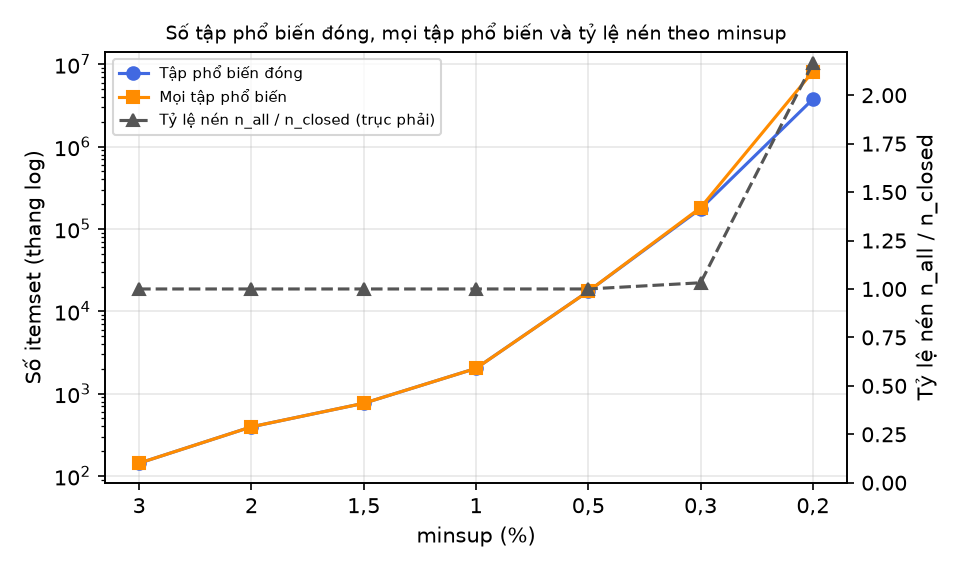

In [34]:
survey_fig = mb.plot_minsup_survey(survey, APP / 'results' / 'figures' / 'minsup_survey.png')
display(Image(filename=str(survey_fig)))

**Kết quả.** Khi minsup giảm từ 3% xuống 0,5%, số tập đóng tăng từ 143 lên 17.498 và luôn bằng số tập phổ biến (tỷ lệ nén 1,0): trên dữ liệu rất thưa, hầu như không có tập nào mà mọi hóa đơn chứa nó đều chứa thêm một sản phẩm chung khác. Tỷ lệ nén chỉ vượt 1 ở 0,3% (1,03) và đạt 2,16 ở 0,2%, trái ngược với dữ liệu dày ở Chương 2 (Mushrooms ở minsup 20% có 1.197 tập đóng so với 53.583 tập phổ biến); lợi ích nén của tập đóng phụ thuộc mạnh vào mật độ dữ liệu. Từ 0,3% xuống 0,2%, số tập đóng tăng đột biến 21 lần (lên 3,77 triệu); nguyên nhân được kiểm chứng ở mục 5.1. Ngưỡng 1% được chọn để sinh luật, vì mỗi mẫu dựa trên ít nhất 198 hóa đơn và số tập phổ biến vừa phải (2.026, trong đó 1.197 tập có từ hai sản phẩm).

### 5.1 Ảnh hưởng của hóa đơn rất dài

Phần này kiểm chứng hai câu hỏi: (1) bước nhảy ở minsup 0,2% có phải do một số ít hóa đơn rất dài gây ra không; (2) kết quả ở minsup 1% phụ thuộc vào các hóa đơn này đến mức nào. Các hóa đơn có từ $t$ sản phẩm trở lên ($t$ thuộc `LONG_THRESHOLDS`) được loại bỏ, rồi FPClose được chạy lại ở các mức trong `LONG_MINSUPS`; minsup tương đối được tính trên số giao dịch còn lại. Ở minsup 1%, toàn bộ luật sinh trên dữ liệu đã loại các hóa đơn có từ `LONG_RULES_MAX_LEN` sản phẩm trở lên được đối chiếu với top-10 theo lift của dữ liệu gốc.

In [35]:
long_check = mb.long_invoice_check(ROOT, APP, transactions, item_map, LONG_THRESHOLDS, LONG_MINSUPS,
                                   OUT_DIR / 'long_invoice', timeout=SURVEY_TIMEOUT, baseline=survey)
long_check.to_csv(APP / 'results' / 'long_invoice_check.csv', index=False, encoding='utf-8')
display(mb.styled(long_check))

max_len,n_removed,n_transactions,minsup_pct,minsup_count,n_closed,n_all,compression,status
gốc,0,19773,1.000000,198,2026,2026,1.000000,ok
gốc,0,19773,0.200000,40,3771107,8163271,2.164688,ok
500,49,19724,1.000000,198,1668,1668,1.000000,ok
500,49,19724,0.200000,40,424270,3061657,7.216294,ok
200,236,19537,1.000000,196,1267,1267,1.000000,ok
200,236,19537,0.200000,40,207356,2845022,13.720471,ok


In [36]:
long_rules_check, long_rules_info, long_rules_lt = mb.long_invoice_rules_check(
    ROOT, APP, transactions, item_map, MINSUP, MINCONF, LONG_RULES_MAX_LEN, TOP_K,
    OUT_DIR / 'long_invoice' / 'rules', timeout=SURVEY_TIMEOUT)
long_rules_check.to_csv(APP / 'results' / 'long_invoice_rules_check.csv', index=False, encoding='utf-8')
print(long_rules_info)
display(mb.styled(long_rules_check))

{'n_rules_goc': 574, 'n_rules_lt200': 296, 'n_removed': 236, 'n_transactions_lt': 19537}


rank_gốc,antecedent,consequent,support_gốc,lift_gốc,có trong lt200,rank_lt200,lift_lt200
1,HERB MARKER THYME [22916],HERB MARKER ROSEMARY [22917] + HERB MARKER PARSLEY [22918],0.010267,78.773800,False,không đạt ngưỡng,nan
2,HERB MARKER ROSEMARY [22917] + HERB MARKER PARSLEY [22918],HERB MARKER THYME [22916],0.010267,78.773800,False,không đạt ngưỡng,nan
3,HERB MARKER THYME [22916] + HERB MARKER PARSLEY [22918],HERB MARKER ROSEMARY [22917],0.010267,78.519542,False,không đạt ngưỡng,nan
4,HERB MARKER ROSEMARY [22917],HERB MARKER THYME [22916] + HERB MARKER PARSLEY [22918],0.010267,78.519542,False,không đạt ngưỡng,nan
5,HERB MARKER THYME [22916] + HERB MARKER BASIL [22920],HERB MARKER ROSEMARY [22917],0.010115,78.464286,False,không đạt ngưỡng,nan
6,HERB MARKER ROSEMARY [22917],HERB MARKER THYME [22916] + HERB MARKER BASIL [22920],0.010115,78.464286,False,không đạt ngưỡng,nan
7,HERB MARKER ROSEMARY [22917] + HERB MARKER BASIL [22920],HERB MARKER THYME [22916],0.010115,77.972318,False,không đạt ngưỡng,nan
8,HERB MARKER THYME [22916],HERB MARKER ROSEMARY [22917] + HERB MARKER BASIL [22920],0.010115,77.972318,False,không đạt ngưỡng,nan
9,HERB MARKER THYME [22916],HERB MARKER ROSEMARY [22917],0.011177,76.825475,True,1,84.952666
10,HERB MARKER ROSEMARY [22917],HERB MARKER THYME [22916],0.011177,76.825475,True,2,84.952666


**Kết quả.**

| Dữ liệu | Số hóa đơn bị loại | Tập đóng ở 0,2% | Tập đóng ở 1% | Số luật ở 1% |
|---|---|---|---|---|
| Gốc | 0 | 3,77 triệu | 2.026 | 574 |
| Loại hóa đơn từ 500 sản phẩm | 49 (0,25%) | 424 nghìn | 1.668 | – |
| Loại hóa đơn từ 200 sản phẩm | 236 (1,2%) | 207 nghìn | 1.267 | 296 |

Câu hỏi (1) được xác nhận: khi loại 49 hóa đơn có từ 500 sản phẩm trở lên (0,25% số giao dịch), số tập đóng ở minsup 0,2% giảm từ 3.771.107 xuống 424.270, tức khoảng 88,7%. Số lượng tập đóng vì vậy rất nhạy với nhóm hóa đơn cực dài này; tuy nhiên kết quả không có nghĩa mọi tập bị mất chỉ xuất hiện trong các hóa đơn đó, vì việc loại hóa đơn cũng làm thay đổi tập nào là tập đóng trong phần dữ liệu còn lại. Ở minsup 1%, ảnh hưởng cũng đáng kể: khi loại 236 hóa đơn có từ 200 sản phẩm trở lên (1,2% số giao dịch), số luật giảm từ 574 xuống 296 (khoảng 48,4%), và tám trong mười luật của top-10 theo lift (tách từ các tập ba sản phẩm Herb Marker) không còn đạt ngưỡng; chỉ cặp Thyme ↔ Rosemary còn lại, với lift tăng từ 76,8 lên 85,0. Kết quả chính ở mục 6–7 vẫn được tính trên toàn bộ dữ liệu, vì các hóa đơn này là giao dịch thực của cửa hàng; mức độ phụ thuộc của từng luật được sử dụng khi diễn giải ở mục 8.

## 6. Sinh luật kết hợp

Gọi $N$ là tổng số giao dịch và $\sigma(X)$ là số giao dịch chứa itemset $X$. Với luật $A \rightarrow B$, trong đó $A$ và $B$ là hai itemset khác rỗng, rời nhau:

$$\text{support}(A \rightarrow B) = \frac{\sigma(A \cup B)}{N}, \qquad \text{confidence}(A \rightarrow B) = \frac{\sigma(A \cup B)}{\sigma(A)}, \qquad \text{lift}(A \rightarrow B) = \frac{\text{confidence}(A \rightarrow B)}{\sigma(B) / N}.$$

Confidence ước lượng xác suất có điều kiện $P(B \mid A)$. Lift so sánh confidence với tỷ lệ nền $\sigma(B)/N$: lift lớn hơn 1 nghĩa là $A$ và $B$ cùng xuất hiện trong một hóa đơn thường xuyên hơn mức kỳ vọng nếu hai sự kiện độc lập. Đây là mối liên hệ thống kê, không thể hiện quan hệ nhân quả hay thứ tự mua hàng.

`demo.jl` sinh luật từ mọi tập phổ biến $Z$ (khôi phục từ tập đóng) bằng cách tách $Z = A \cup B$; vì $Z$ phổ biến nên $\text{support}(A \cup B) \ge \text{minsup}$, và luật được giữ khi confidence đạt `MINCONF`. Toàn bộ luật được ghi trong một lần chạy và đã được xếp theo lift giảm dần (khi bằng nhau thì xét confidence, support, rồi thứ tự từ điển), giống tiêu chí của tùy chọn `--top k`; do đó top-10 ở mục 7.1 là mười luật đầu tiên của file.

In [37]:
rules_all_run = mb.run_fpclose(ROOT, TX_PATH, MINSUP, OUT_DIR, minconf=MINCONF, timeout=SURVEY_TIMEOUT)
print(f"Toàn bộ luật ở minsup = {MINSUP}, minconf = {MINCONF}: {rules_all_run['info'].get('rules_written')} luật "
      f"-> {rules_all_run['rules']}")

Toàn bộ luật ở minsup = 0.01, minconf = 0.6: 574 luật -> C:\HCMUS\Data Mining\FPClose\FPClose\applications\application_01\out\rules_ms0.01_mc0.6_all.txt


In [38]:
all_rules = mb.read_rules(rules_all_run['rules'], item_map)
all_rules.to_csv(APP / 'results' / 'all_rules.csv', index=False, encoding='utf-8')
assert len(all_rules) == rules_all_run['info'].get('rules_generated', len(all_rules)), 'số luật đọc được khác số demo.jl báo'
print('Số luật đạt hai ngưỡng:', len(all_rules))
z_size = all_rules['antecedent_ids'].str.split().str.len() + all_rules['consequent_ids'].str.split().str.len()
display(mb.styled(z_size.value_counts().sort_index().rename_axis('kích thước |A ∪ B|').reset_index(name='số luật')))

Số luật đạt hai ngưỡng: 574


kích thước |A ∪ B|,số luật
2,122
3,341
4,96
5,15


## 7. Các luật kết hợp tiêu biểu

### 7.1 Top-10 luật theo lift

Top-10 là mười luật đầu tiên của bảng toàn bộ luật, hiển thị theo dạng "TÊN [StockCode]". Để kiểm tra độc lập với FPClose, support, confidence và lift của **toàn bộ** luật được tính lại bằng phép đếm trực tiếp trên tập giao dịch; một luật được xem là khớp khi số đếm bằng nhau và sai số của cả ba độ đo nhỏ hơn $10^{-9}$.

In [39]:
top10_rules = all_rules[all_rules['rank'] <= TOP_K].reset_index(drop=True)   # all_rules đã xếp theo lift như --top
top10_rules.to_csv(APP / 'results' / 'top10_rules.csv', index=False, encoding='utf-8')
display(mb.styled(top10_rules[['rank', 'antecedent', 'consequent', 'support', 'confidence', 'lift', 'count']]))

rank,antecedent,consequent,support,confidence,lift,count
1,HERB MARKER THYME [22916],HERB MARKER ROSEMARY [22917] + HERB MARKER PARSLEY [22918],0.010267,0.856540,78.773800,203
2,HERB MARKER ROSEMARY [22917] + HERB MARKER PARSLEY [22918],HERB MARKER THYME [22916],0.010267,0.944186,78.773800,203
3,HERB MARKER THYME [22916] + HERB MARKER PARSLEY [22918],HERB MARKER ROSEMARY [22917],0.010267,0.953052,78.519542,203
4,HERB MARKER ROSEMARY [22917],HERB MARKER THYME [22916] + HERB MARKER PARSLEY [22918],0.010267,0.845833,78.519542,203
5,HERB MARKER THYME [22916] + HERB MARKER BASIL [22920],HERB MARKER ROSEMARY [22917],0.010115,0.952381,78.464286,200
6,HERB MARKER ROSEMARY [22917],HERB MARKER THYME [22916] + HERB MARKER BASIL [22920],0.010115,0.833333,78.464286,200
7,HERB MARKER ROSEMARY [22917] + HERB MARKER BASIL [22920],HERB MARKER THYME [22916],0.010115,0.934579,77.972318,200
8,HERB MARKER THYME [22916],HERB MARKER ROSEMARY [22917] + HERB MARKER BASIL [22920],0.010115,0.843882,77.972318,200
9,HERB MARKER THYME [22916],HERB MARKER ROSEMARY [22917],0.011177,0.932489,76.825475,221
10,HERB MARKER ROSEMARY [22917],HERB MARKER THYME [22916],0.011177,0.920833,76.825475,221


In [40]:
rule_check = mb.verify_rules(all_rules, transactions)
rule_check.to_csv(APP / 'results' / 'rule_verification.csv', index=False, encoding='utf-8')
print(f"{int(rule_check['khớp'].sum())}/{len(rule_check)} luật khớp (minsup = {MINSUP})")
assert rule_check['khớp'].all(), 'Có luật không khớp với phép đếm trực tiếp'

574/574 luật khớp (minsup = 0.01)


**Kết quả.** Cả mười luật đều thuộc bộ que cắm cây gia vị (Herb Marker: Thyme, Rosemary, Parsley, Basil), với lift từ 76,8 đến 78,8 và confidence từ 0,83 đến 0,95: trong các hóa đơn chứa vế trái, tỷ lệ chứa vế phải cao gấp gần 80 lần tỷ lệ chung. Support chỉ từ 1,01% đến 1,12% (200–221 hóa đơn), sát ngưỡng minsup, và các luật xuất hiện theo cặp đối xứng có cùng lift. Theo mục 5.1, tám luật trong số này phụ thuộc vào các hóa đơn rất dài; chỉ cặp Thyme ↔ Rosemary vẫn đạt ngưỡng khi loại các hóa đơn đó.

Toàn bộ 574/574 luật khớp với phép đếm trực tiếp. Phép kiểm tra này xác nhận mọi luật được sinh ra đều đúng; tính đầy đủ của tập luật dựa trên tính đúng đắn của tập phổ biến (đã đối chiếu với SPMF ở Chương 2) và bộ kiểm thử của bước sinh luật.

### 7.2 Top-10 luật đa dạng

Top-10 theo lift bị chi phối bởi một họ sản phẩm và các cặp luật đối xứng, vì $\text{lift}(A \rightarrow B) = \text{lift}(B \rightarrow A)$. Để có cái nhìn rộng hơn, các luật được duyệt theo cùng thứ tự với mục 7.1, và một luật chỉ được nhận khi không có sản phẩm nào của nó đã xuất hiện trong các luật đã nhận. Cách lọc chỉ chọn lại trong các luật do FPClose sinh ra; cột `rank_all` giữ thứ hạng gốc của luật. Ô thứ hai đối chiếu các luật này với dữ liệu đã loại các hóa đơn rất dài (mục 5.1).

In [41]:
top10_diverse = mb.diverse_top_rules(all_rules, TOP_K, mode='item')
top10_diverse.to_csv(APP / 'results' / 'top10_rules_diverse.csv', index=False, encoding='utf-8')
display(mb.styled(top10_diverse[RULE_COLS]))

rank_all,antecedent,consequent,support,confidence,lift,count
1,HERB MARKER THYME [22916],HERB MARKER ROSEMARY [22917] + HERB MARKER PARSLEY [22918],0.010267,0.856540,78.773800,203
31,HERB MARKER MINT [22919],HERB MARKER BASIL [22920],0.010519,0.866667,70.812397,208
33,REGENCY TEA PLATE PINK [23172],REGENCY TEA PLATE ROSES [23170] + REGENCY TEA PLATE GREEN [23171],0.012896,0.836066,51.822961,255
40,SET OF 3 WOODEN TREE DECORATIONS [23265],SET OF 3 WOODEN STOCKING DECORATION [23266],0.011076,0.747440,46.329582,219
42,REGENCY SUGAR BOWL GREEN [23174],REGENCY MILK JUG PINK [23175],0.012289,0.754658,45.355198,243
44,POPPY'S PLAYHOUSE LIVINGROOM [22746],POPPY'S PLAYHOUSE BEDROOM [22745] + POPPY'S PLAYHOUSE KITCHEN [22748],0.011329,0.682927,43.142211,224
46,JAM JAR WITH GREEN LID [22963],JAM JAR WITH PINK LID [22962],0.011531,0.742671,42.938111,228
50,PINK POLKADOT CUP [21239],BLUE POLKADOT CUP [21240],0.010519,0.677524,41.220586,208
52,CHILDRENS CUTLERY DOLLY GIRL [23254],CHILDRENS CUTLERY SPACEBOY [23256],0.011531,0.762542,40.972117,228
61,BLUE POLKADOT BOWL [20675],PINK POLKADOT BOWL [20677],0.010519,0.645963,38.356220,208


**Kết quả.** Mười luật không có sản phẩm chung, thuộc các dòng que cắm cây gia vị, đồ Regency (đĩa trà; bộ đường – bình sữa), đồ trang trí Giáng sinh bằng gỗ, bộ phòng đồ chơi Poppy's Playhouse, hũ mứt, cốc và bát chấm bi, và bộ dao nĩa trẻ em, với lift từ 38 đến 79 và confidence từ 0,65 đến 0,87. Cách lọc chỉ bảo đảm không trùng mã sản phẩm, nên một số dòng sản phẩm xuất hiện ở hai luật. Điểm chung của cả mười luật là các biến thể khác màu hoặc khác mẫu của cùng một bộ sưu tập.

In [42]:
# Đối chiếu top-10 đa dạng ở MINSUP với toàn bộ luật trên dữ liệu đã bỏ hóa đơn >= LONG_RULES_MAX_LEN sản phẩm.
# Dùng lại luật đã sinh ở mục 5.1 (biến long_rules_lt hoặc file luật); chỉ chạy lại khi chưa có cả hai.
lt_rules_file = mb.rules_path(OUT_DIR / 'long_invoice' / 'rules' / f'lt{LONG_RULES_MAX_LEN}', MINSUP, MINCONF)
if 'long_rules_lt' in globals():
    rules_lt = long_rules_lt
elif lt_rules_file.exists():
    rules_lt = mb.read_rules(lt_rules_file, item_map)
else:
    _, _, rules_lt = mb.long_invoice_rules_check(ROOT, APP, transactions, item_map, MINSUP, MINCONF,
                                                 LONG_RULES_MAX_LEN, TOP_K, OUT_DIR / 'long_invoice' / 'rules',
                                                 timeout=SURVEY_TIMEOUT)
long_diverse_check = mb.compare_rule_sets(top10_diverse, rules_lt, 'gốc', f'lt{LONG_RULES_MAX_LEN}')
long_diverse_check.to_csv(APP / 'results' / 'long_invoice_diverse_check.csv', index=False, encoding='utf-8')
print(f'Số luật trên dữ liệu đã bỏ hóa đơn >= {LONG_RULES_MAX_LEN} sản phẩm: {len(rules_lt)}')
display(mb.styled(long_diverse_check))

Số luật trên dữ liệu đã bỏ hóa đơn >= 200 sản phẩm: 296


rank_gốc,antecedent,consequent,support_gốc,lift_gốc,có trong lt200,rank_lt200,lift_lt200
1,HERB MARKER THYME [22916],HERB MARKER ROSEMARY [22917] + HERB MARKER PARSLEY [22918],0.010267,78.773800,False,không đạt ngưỡng,nan
31,HERB MARKER MINT [22919],HERB MARKER BASIL [22920],0.010519,70.812397,False,không đạt ngưỡng,nan
33,REGENCY TEA PLATE PINK [23172],REGENCY TEA PLATE ROSES [23170] + REGENCY TEA PLATE GREEN [23171],0.012896,51.822961,True,7,63.391854
40,SET OF 3 WOODEN TREE DECORATIONS [23265],SET OF 3 WOODEN STOCKING DECORATION [23266],0.011076,46.329582,False,không đạt ngưỡng,nan
42,REGENCY SUGAR BOWL GREEN [23174],REGENCY MILK JUG PINK [23175],0.012289,45.355198,True,13,52.421259
44,POPPY'S PLAYHOUSE LIVINGROOM [22746],POPPY'S PLAYHOUSE BEDROOM [22745] + POPPY'S PLAYHOUSE KITCHEN [22748],0.011329,43.142211,True,16,49.357962
46,JAM JAR WITH GREEN LID [22963],JAM JAR WITH PINK LID [22962],0.011531,42.938111,False,không đạt ngưỡng,nan
50,PINK POLKADOT CUP [21239],BLUE POLKADOT CUP [21240],0.010519,41.220586,True,21,46.557387
52,CHILDRENS CUTLERY DOLLY GIRL [23254],CHILDRENS CUTLERY SPACEBOY [23256],0.011531,40.972117,True,26,43.614590
61,BLUE POLKADOT BOWL [20675],PINK POLKADOT BOWL [20677],0.010519,38.356220,True,30,42.910217


**Kết quả.** Khi loại các hóa đơn có từ 200 sản phẩm trở lên, sáu luật vẫn đạt ngưỡng với lift tăng (đĩa trà và bộ đường – bình sữa Regency, Poppy's Playhouse, cốc và bát chấm bi, bộ dao nĩa trẻ em), còn bốn luật không còn đạt ngưỡng (hai luật que cắm cây gia vị, đồ trang trí Giáng sinh bằng gỗ, hũ mứt). Nhóm thứ nhất ổn định trong phép kiểm tra này; nhóm thứ hai phụ thuộc chủ yếu vào các hóa đơn rất dài.

### 7.3 Độ nhạy theo minsup

FPClose được chạy lại ở `MINSUP_SENS` = 2% với cùng `MINCONF`. Tập luật ở 2% là tập con của tập luật ở 1% (với cùng confidence và lift), nên phép so sánh cho biết luật tiêu biểu nào vẫn đạt ngưỡng cao hơn. Toàn bộ luật ở 2% cũng được kiểm tra chéo theo cùng cách ở mục 7.1.

In [43]:
sens_run = mb.run_fpclose(ROOT, TX_PATH, MINSUP_SENS, OUT_DIR, minconf=MINCONF, timeout=SURVEY_TIMEOUT)
print(f"minsup = {MINSUP_SENS}, minconf = {MINCONF}: {sens_run['info'].get('rules_generated')} luật "
      f"(toàn bộ) -> {sens_run['rules']}")

rules_sens = mb.read_rules(sens_run['rules'], item_map)
assert len(rules_sens) == sens_run['info'].get('rules_generated', len(rules_sens)), 'số luật đọc được khác số demo.jl báo'
print(f'Số luật ở minsup = {MINSUP_SENS}: {len(rules_sens)}')

sens_check = mb.verify_rules(rules_sens, transactions)
sens_check.to_csv(APP / 'results' / f'rule_verification_ms{MINSUP_SENS}.csv', index=False, encoding='utf-8')
print(f"{int(sens_check['khớp'].sum())}/{len(sens_check)} luật khớp (minsup = {MINSUP_SENS})")
assert sens_check['khớp'].all(), f'Có luật không khớp với phép đếm trực tiếp (minsup = {MINSUP_SENS})'

minsup = 0.02, minconf = 0.6: 30 luật (toàn bộ) -> C:\HCMUS\Data Mining\FPClose\FPClose\applications\application_01\out\rules_ms0.02_mc0.6_all.txt
Số luật ở minsup = 0.02: 30
30/30 luật khớp (minsup = 0.02)


In [44]:
diverse_sens = mb.diverse_top_rules(rules_sens, TOP_K, mode='item')
diverse_sens.to_csv(APP / 'results' / f'top10_rules_diverse_ms{MINSUP_SENS}.csv', index=False, encoding='utf-8')
display(mb.styled(diverse_sens[RULE_COLS]))

sensitivity = mb.compare_rule_sets(top10_diverse, rules_sens, f'ms{MINSUP}', f'ms{MINSUP_SENS}')
sensitivity.to_csv(APP / 'results' / 'sensitivity_minsup.csv', index=False, encoding='utf-8')
display(mb.styled(sensitivity))

rank_all,antecedent,consequent,support,confidence,lift,count
1,PINK REGENCY TEACUP AND SAUCER [22698],GREEN REGENCY TEACUP AND SAUCER [22697] + ROSES REGENCY TEACUP AND SAUCER [22699],0.027361,0.707190,18.231107,541
7,GARDENERS KNEELING PAD CUP OF TEA [23300],GARDENERS KNEELING PAD KEEP CALM [23301],0.027613,0.720317,15.600023,546
13,DOLLY GIRL LUNCH BOX [22630],SPACEBOY LUNCH BOX [22629],0.027209,0.632941,13.905718,538
14,JUMBO BAG PEARS [23200],JUMBO BAG APPLES [23199],0.020533,0.682353,13.795669,406
15,CHARLOTTE BAG PINK POLKADOT [22356],RED RETROSPOT CHARLOTTE BAG [20724],0.026400,0.703504,13.479056,522
17,ALARM CLOCK BAKELIKE RED [22727],ALARM CLOCK BAKELIKE GREEN [22726],0.032367,0.608944,12.286374,640
20,PAPER CHAIN KIT VINTAGE CHRISTMAS [22910],PAPER CHAIN KIT 50'S CHRISTMAS [22086],0.027917,0.673171,11.474659,552
22,JUMBO STORAGE BAG SUKI [21931] + JUMBO BAG PINK POLKADOT [22386],JUMBO BAG RED RETROSPOT [85099B],0.020887,0.801942,7.590615,413
29,RED HANGING HEART T-LIGHT HOLDER [21733],WHITE HANGING HEART T-LIGHT HOLDER [85123A],0.025135,0.670715,5.855211,497


rank_ms0.01,antecedent,consequent,support_ms0.01,lift_ms0.01,có trong ms0.02,rank_ms0.02,lift_ms0.02
1,HERB MARKER THYME [22916],HERB MARKER ROSEMARY [22917] + HERB MARKER PARSLEY [22918],0.010267,78.773800,False,không đạt ngưỡng,None
31,HERB MARKER MINT [22919],HERB MARKER BASIL [22920],0.010519,70.812397,False,không đạt ngưỡng,None
33,REGENCY TEA PLATE PINK [23172],REGENCY TEA PLATE ROSES [23170] + REGENCY TEA PLATE GREEN [23171],0.012896,51.822961,False,không đạt ngưỡng,None
40,SET OF 3 WOODEN TREE DECORATIONS [23265],SET OF 3 WOODEN STOCKING DECORATION [23266],0.011076,46.329582,False,không đạt ngưỡng,None
42,REGENCY SUGAR BOWL GREEN [23174],REGENCY MILK JUG PINK [23175],0.012289,45.355198,False,không đạt ngưỡng,None
44,POPPY'S PLAYHOUSE LIVINGROOM [22746],POPPY'S PLAYHOUSE BEDROOM [22745] + POPPY'S PLAYHOUSE KITCHEN [22748],0.011329,43.142211,False,không đạt ngưỡng,None
46,JAM JAR WITH GREEN LID [22963],JAM JAR WITH PINK LID [22962],0.011531,42.938111,False,không đạt ngưỡng,None
50,PINK POLKADOT CUP [21239],BLUE POLKADOT CUP [21240],0.010519,41.220586,False,không đạt ngưỡng,None
52,CHILDRENS CUTLERY DOLLY GIRL [23254],CHILDRENS CUTLERY SPACEBOY [23256],0.011531,40.972117,False,không đạt ngưỡng,None
61,BLUE POLKADOT BOWL [20675],PINK POLKADOT BOWL [20677],0.010519,38.356220,False,không đạt ngưỡng,None


**Kết quả.** Ở minsup 2% chỉ còn 30 luật; bảng đa dạng chỉ gồm 9 luật vì không đủ mười luật có tập sản phẩm rời nhau. Đứng đầu là bộ tách trà Regency (lift 18,2), tiếp theo là đệm quỳ làm vườn, hộp cơm trẻ em, túi Jumbo Bag, túi Charlotte, đồng hồ Bakelike, dây xích giấy Giáng sinh và giá nến Hanging Heart (lift từ 5,9 đến 15,6). Không luật nào trong top-10 đa dạng ở 1% đạt ngưỡng 2%, vì support của chúng chỉ từ 1,03% đến 1,29%. Như vậy các luật cụ thể thay đổi theo minsup (ở 1% là các bộ sưu tập ngách với lift rất cao, ở 2% là các bộ sưu tập bán chạy với lift thấp hơn), nhưng kiểu đồng xuất hiện giữa các biến thể của cùng một bộ sưu tập vẫn ổn định ở cả hai mức. 30/30 luật khớp với phép đếm trực tiếp.

## 8. Diễn giải ý nghĩa kinh doanh

### 8.1 Các phát hiện chính

1. **Khách hàng mua nhiều biến thể của cùng một bộ sưu tập.** Hầu hết các luật có lift cao, ở cả minsup 1% và 2%, nối các sản phẩm cùng dòng nhưng khác màu hoặc khác mẫu (mục 7).
2. **Các hóa đơn rất dài có ảnh hưởng đáng kể.** Khi loại 236 hóa đơn có từ 200 sản phẩm trở lên (1,2% số giao dịch), số luật ở minsup 1% giảm từ 574 xuống 296 (khoảng 48,4%). Một số mẫu vẫn đạt ngưỡng sau khi loại các hóa đơn này (đồ bàn ăn Regency, đồ chấm bi, đồ dùng trẻ em, cặp que cắm Thyme ↔ Rosemary); một số khác không còn đạt ngưỡng (trọn bộ que cắm cây gia vị, đồ trang trí Giáng sinh bằng gỗ, hũ mứt) (mục 5.1 và 7.2).
3. **Lift cao và phạm vi rộng là hai tiêu chí khác nhau.** Các luật có lift cao nhất ở minsup 1% chỉ có support khoảng 1,0–1,3%; các luật về tách trà Regency ở minsup 2% có lift thấp hơn (14,5–18,2) nhưng xuất hiện trong 2,7–3,2% số hóa đơn (mục 7.3).

### 8.2 Khuyến nghị

- **Gợi ý "hoàn thiện bộ sưu tập":** khi khách hàng chọn một biến thể, hệ thống gợi ý các biến thể còn lại của cùng bộ sưu tập. Các luật vẫn đạt ngưỡng khi loại hóa đơn rất dài nên được ưu tiên thử nghiệm trước, và cần được đánh giá riêng trên từng phân khúc khách hàng trước khi áp dụng rộng.
- **Gói sản phẩm theo bộ:** các mẫu gắn với hóa đơn rất dài (trọn bộ que cắm cây gia vị, đồ trang trí Giáng sinh, hũ mứt) phù hợp để thử nghiệm dưới dạng gói sản phẩm hoặc giá theo bộ cho đơn hàng số lượng lớn.
- **Chọn luật theo mục tiêu:** luật có support cao phù hợp cho khuyến mãi diện rộng; luật có lift cao phù hợp cho gợi ý có mục tiêu.
- **Lập kế hoạch tồn kho theo bộ sưu tập,** vì các biến thể thường được mua cùng nhau.

Vì luật kết hợp chỉ phản ánh sự đồng xuất hiện, hiệu quả của các khuyến nghị trên cần được kiểm chứng bằng thử nghiệm (ví dụ thử nghiệm A/B) trước khi triển khai.

### 8.3 Hạn chế và hướng mở rộng

- **Đồng xuất hiện không phải nhân quả:** luật không cho biết việc gợi ý một sản phẩm có làm tăng doanh số của sản phẩm kia hay không.
- **Độ dài hóa đơn chỉ là dấu hiệu gián tiếp của đơn hàng bán sỉ,** vì dữ liệu không ghi nhận loại khách hàng. Hướng mở rộng: xác định phân khúc khách hàng qua CustomerID và lịch sử mua hàng, rồi khai thác riêng từng phân khúc.
- **Mỗi biến thể là một StockCode riêng,** nên các luật chủ yếu nối các biến thể cùng dòng. Hướng mở rộng: gộp các biến thể thành dòng sản phẩm để tìm quan hệ giữa các dòng sản phẩm khác nhau.
- **Số lượng, đơn giá và thời gian mua không được sử dụng,** nên luật không phản ánh doanh thu hay tính mùa vụ; dữ liệu chỉ thuộc một cửa hàng tại Vương quốc Anh trong giai đoạn 2010–2011.